In [ ]:
# Task 1 : Dataset Exploration
import tensorflow as tf

dataset_url = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz"
annotations_url = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz"

images_path = tf.keras.utils.get_file(
    "images.tar.gz",
    origin=dataset_url,
    extract=True
)

annotations_path = tf.keras.utils.get_file(
    "annotations.tar.gz",
    origin=annotations_url,
    extract=True
)

print(images_path)
print(annotations_path)

791918971/791918971 ━━━━━━━━━━━━━━━━━━━━ 23s 0us/step
19173078/19173078 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
/root/.keras/datasets/images_extracted
/root/.keras/datasets/annotations_extracted


In [ ]:
import os
from collections import Counter

images_dir = "/root/.keras/datasets/images_extracted/images"
annotations_dir = "/root/.keras/datasets/annotations_extracted/annotations"

image_files = [
    f for f in os.listdir(images_dir)
    if f.endswith(".jpg")
]

classes = sorted(set(
    "_".join(filename.split("_")[:-1])
    for filename in image_files
))

print("Number of images:", len(image_files))
print("Number of classes:", len(classes))

print("\nClasses:")
for i, cls in enumerate(classes):
    print(i, ":", cls)

Number of images: 7390
Number of classes: 37

Classes:
0 : Abyssinian
1 : Bengal
2 : Birman
3 : Bombay
4 : British_Shorthair
5 : Egyptian_Mau
6 : Maine_Coon
7 : Persian
8 : Ragdoll
9 : Russian_Blue
10 : Siamese
11 : Sphynx
12 : american_bulldog
13 : american_pit_bull_terrier
14 : basset_hound
15 : beagle
16 : boxer
17 : chihuahua
18 : english_cocker_spaniel
19 : english_setter
20 : german_shorthaired
21 : great_pyrenees
22 : havanese
23 : japanese_chin
24 : keeshond
25 : leonberger
26 : miniature_pinscher
27 : newfoundland
28 : pomeranian
29 : pug
30 : saint_bernard
31 : samoyed
32 : scottish_terrier
33 : shiba_inu
34 : staffordshire_bull_terrier
35 : wheaten_terrier
36 : yorkshire_terrier


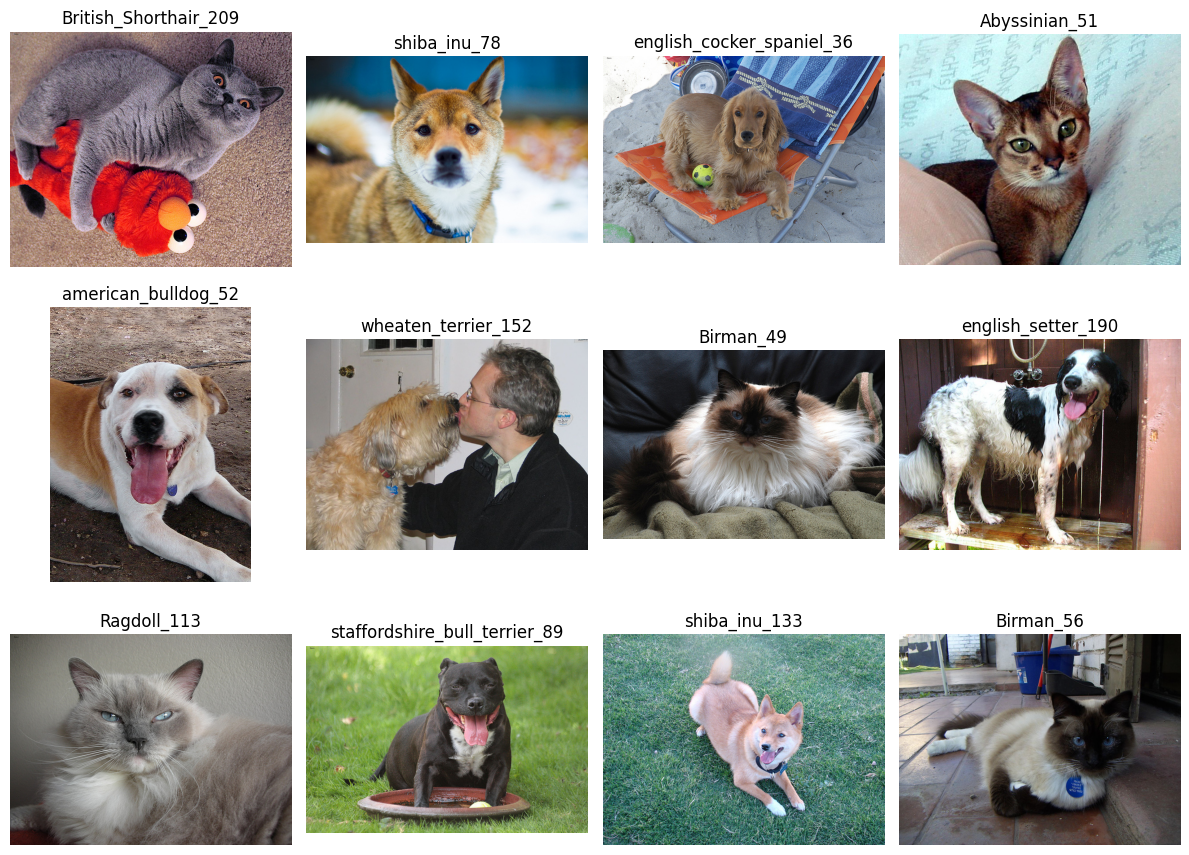

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

sample_images = random.sample(image_files, 12)

plt.figure(figsize=(12, 9))

for i, filename in enumerate(sample_images):
    image_path = os.path.join(images_dir, filename)
    image = Image.open(image_path)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(filename.rsplit(".", 1)[0])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np

image_paths = []
labels = []

class_to_index = {
    cls: i for i, cls in enumerate(classes)
}

for filename in image_files:
    class_name = "_".join(filename.split("_")[:-1])

    image_paths.append(
        os.path.join(images_dir, filename)
    )

    labels.append(class_to_index[class_name])

image_paths = np.array(image_paths)
labels = np.array(labels)

print("Total images:", len(image_paths))
print("Number of classes:", len(classes))

Total images: 7390
Number of classes: 37


In [ ]:
from sklearn.model_selection import train_test_split

# 80% training, 20% temporary
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Split the remaining 20% equally
# 10% validation, 10% test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Training samples  :", len(train_paths))
print("Validation samples:", len(val_paths))
print("Test samples      :", len(test_paths))

Training samples  : 5912
Validation samples: 739
Test samples      : 739


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def load_and_preprocess(path, label):

    # Load image
    image = tf.io.read_file(path)

    # Decode as RGB
    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    # Resize to 224 × 224
    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    # MobileNetV2 preprocessing
    image = preprocess_input(image)

    return image, label

In [ ]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

In [ ]:
train_ds = train_ds.map(
    load_and_preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    load_and_preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    load_and_preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

In [ ]:
train_ds = (
    train_ds
    .shuffle(len(train_paths))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    val_ds
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_ds
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

In [ ]:
for images, labels_batch in train_ds.take(1):
    print("Image batch shape :", images.shape)
    print("Label batch shape :", labels_batch.shape)
    print("Image dtype       :", images.dtype)
    print("Pixel minimum     :", tf.reduce_min(images).numpy())
    print("Pixel maximum     :", tf.reduce_max(images).numpy())

Image batch shape : (32, 224, 224, 3)
Label batch shape : (32,)
Image dtype       : <dtype: 'float32'>
Pixel minimum     : -1.0
Pixel maximum     : 1.0


In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
base_model.trainable = False

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(37, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 37)             │        47,397 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,305,381 (8.79 MB)

 Trainable params: 47,397 (185.14 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
initializers = {
    "Zero": tf.keras.initializers.Zeros(),
    "Random": tf.keras.initializers.RandomNormal(mean=0.0, stddev=0.05),
    "Xavier": tf.keras.initializers.GlorotNormal(),
    "He": tf.keras.initializers.HeNormal()
}

In [ ]:
def create_model(initializer):

    base_model = tf.keras.applications.MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    base_model.trainable = False

    model = tf.keras.Sequential([
        base_model,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(
            37,
            activation="softmax",
            kernel_initializer=initializer
        )
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
histories = {}

EPOCHS = 5

for name, initializer in initializers.items():

    print(f"\nTraining with {name} initialization...")

    model_init = create_model(initializer)

    history = model_init.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )

    histories[name] = history


Training with Zero initialization...
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 71s 202ms/step - accuracy: 0.8451 - loss: 0.7635 - val_accuracy: 0.8958 - val_loss: 0.3305
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 38s 48ms/step - accuracy: 0.9432 - loss: 0.2275 - val_accuracy: 0.9066 - val_loss: 0.2872
Epoch 3/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.9611 - loss: 0.1566 - val_accuracy: 0.9202 - val_loss: 0.2580
Epoch 4/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 41s 46ms/step - accuracy: 0.9726 - loss: 0.1121 - val_accuracy: 0.9026 - val_loss: 0.2593
Epoch 5/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 46ms/step - accuracy: 0.9839 - loss: 0.0842 - val_accuracy: 0.9039 - val_loss: 0.2467

Training with Random initialization...
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 44s 114ms/step - accuracy: 0.7652 - loss: 0.9002 - val_accuracy: 0.8904 - val_loss: 0.3815
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.9315 - loss: 0.2588 - val_accuracy: 0.8945 - val_loss: 0.3277
Epoch 3/5
185/185

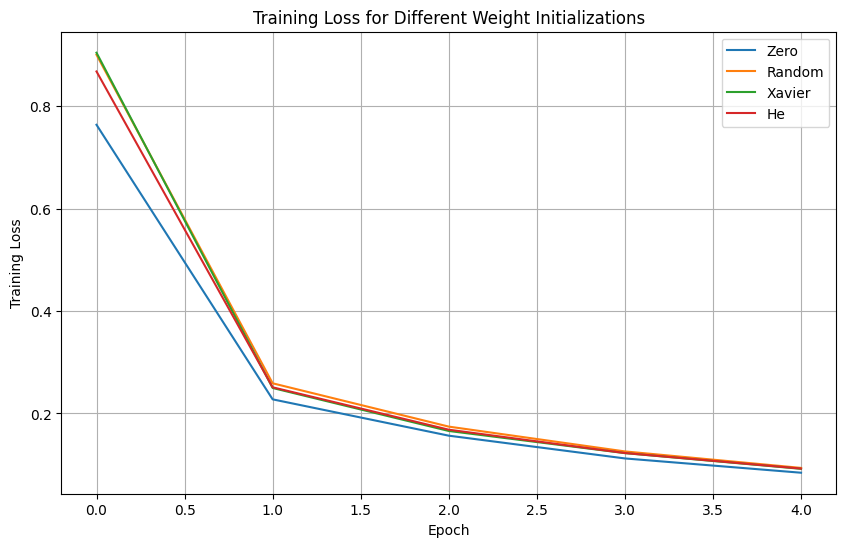

In [ ]:
plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(
        history.history["loss"],
        label=name
    )

plt.title("Training Loss for Different Weight Initializations")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.legend()
plt.grid(True)
plt.show()

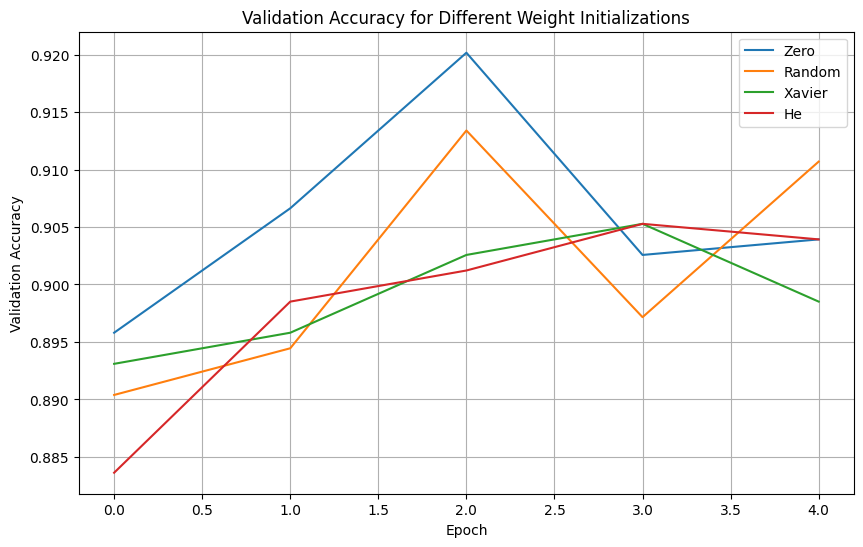

In [ ]:
plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(
        history.history["val_accuracy"],
        label=name
    )

plt.title("Validation Accuracy for Different Weight Initializations")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
for name, history in histories.items():

    final_loss = history.history["loss"][-1]
    final_val_acc = history.history["val_accuracy"][-1]

    print(
        f"{name:10s} | "
        f"Final Training Loss: {final_loss:.4f} | "
        f"Final Validation Accuracy: {final_val_acc:.4f}"
    )

Zero       | Final Training Loss: 0.0842 | Final Validation Accuracy: 0.9039
Random     | Final Training Loss: 0.0936 | Final Validation Accuracy: 0.9107
Xavier     | Final Training Loss: 0.0918 | Final Validation Accuracy: 0.8985
He         | Final Training Loss: 0.0923 | Final Validation Accuracy: 0.9039


In [ ]:
regularization_configs = {
    "No Regularization": {
        "l2": 0.0,
        "dropout": 0.0,
        "batch_norm": False
    },
    "L2": {
        "l2": 0.001,
        "dropout": 0.0,
        "batch_norm": False
    },
    "Dropout": {
        "l2": 0.0,
        "dropout": 0.5,
        "batch_norm": False
    },
    "Batch Normalization": {
        "l2": 0.0,
        "dropout": 0.0,
        "batch_norm": True
    }
}

In [ ]:
def create_regularized_model(l2_value=0.0,
                             dropout_rate=0.0,
                             use_batch_norm=False):

    base_model = tf.keras.applications.MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    base_model.trainable = False

    model = tf.keras.Sequential([
        base_model,
        tf.keras.layers.GlobalAveragePooling2D()
    ])

    if use_batch_norm:
        model.add(tf.keras.layers.BatchNormalization())

    if dropout_rate > 0:
        model.add(tf.keras.layers.Dropout(dropout_rate))

    model.add(
        tf.keras.layers.Dense(
            37,
            activation="softmax",
            kernel_regularizer=(
                tf.keras.regularizers.l2(l2_value)
                if l2_value > 0 else None
            )
        )
    )

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
regularization_histories = {}

EPOCHS = 5

for name, config in regularization_configs.items():

    print(f"\nTraining: {name}")

    model_reg = create_regularized_model(
        l2_value=config["l2"],
        dropout_rate=config["dropout"],
        use_batch_norm=config["batch_norm"]
    )

    history = model_reg.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )

    regularization_histories[name] = history


Training: No Regularization
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 43s 114ms/step - accuracy: 0.7825 - loss: 0.8607 - val_accuracy: 0.8931 - val_loss: 0.3550
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 41ms/step - accuracy: 0.9349 - loss: 0.2471 - val_accuracy: 0.8972 - val_loss: 0.2891
Epoch 3/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.9581 - loss: 0.1639 - val_accuracy: 0.8999 - val_loss: 0.2734
Epoch 4/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 47ms/step - accuracy: 0.9723 - loss: 0.1185 - val_accuracy: 0.8972 - val_loss: 0.2723
Epoch 5/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 46ms/step - accuracy: 0.9822 - loss: 0.0897 - val_accuracy: 0.9175 - val_loss: 0.2547

Training: L2
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 44s 116ms/step - accuracy: 0.7842 - loss: 0.9713 - val_accuracy: 0.8890 - val_loss: 0.4611
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 23s 48ms/step - accuracy: 0.9293 - loss: 0.3609 - val_accuracy: 0.8972 - val_loss: 0.4150
Epoch 3/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 41ms/step

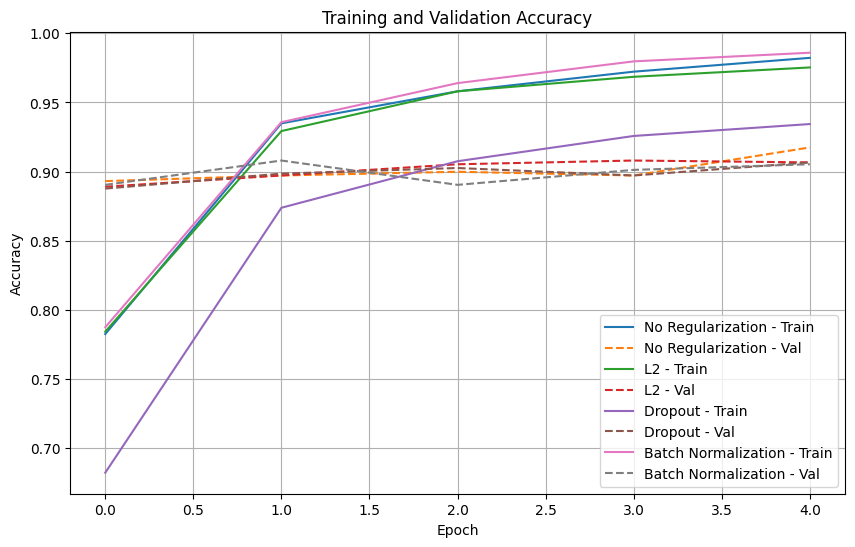

In [ ]:
plt.figure(figsize=(10, 6))

for name, history in regularization_histories.items():
    plt.plot(
        history.history["accuracy"],
        label=f"{name} - Train"
    )
    plt.plot(
        history.history["val_accuracy"],
        linestyle="--",
        label=f"{name} - Val"
    )

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

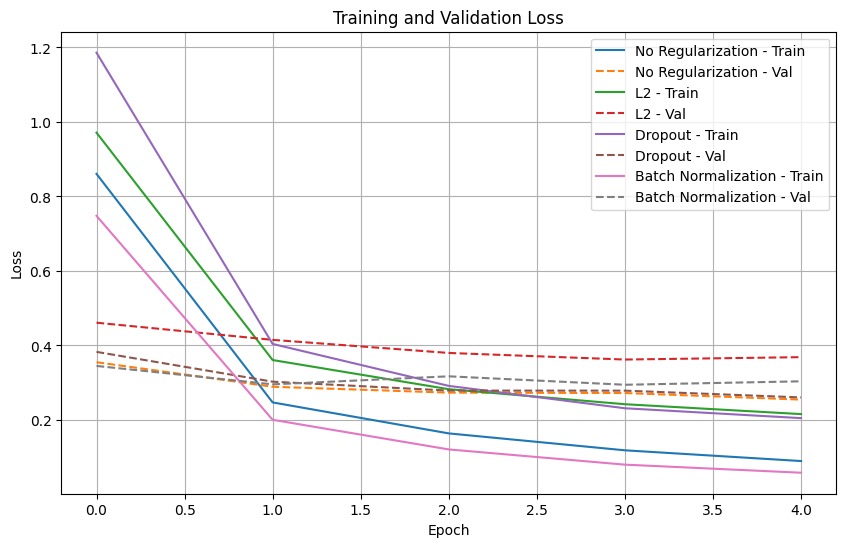

In [ ]:
plt.figure(figsize=(10, 6))

for name, history in regularization_histories.items():
    plt.plot(
        history.history["loss"],
        label=f"{name} - Train"
    )
    plt.plot(
        history.history["val_loss"],
        linestyle="--",
        label=f"{name} - Val"
    )

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
for name, history in regularization_histories.items():

    print(
        f"{name:20s} | "
        f"Train Acc: {history.history['accuracy'][-1]:.4f} | "
        f"Val Acc: {history.history['val_accuracy'][-1]:.4f} | "
        f"Train Loss: {history.history['loss'][-1]:.4f} | "
        f"Val Loss: {history.history['val_loss'][-1]:.4f}"
    )

No Regularization    | Train Acc: 0.9822 | Val Acc: 0.9175 | Train Loss: 0.0897 | Val Loss: 0.2547
L2                   | Train Acc: 0.9753 | Val Acc: 0.9066 | Train Loss: 0.2157 | Val Loss: 0.3686
Dropout              | Train Acc: 0.9344 | Val Acc: 0.9066 | Train Loss: 0.2049 | Val Loss: 0.2605
Batch Normalization  | Train Acc: 0.9860 | Val Acc: 0.9053 | Train Loss: 0.0583 | Val Loss: 0.3037


In [ ]:
def create_bn_model(use_bn=False):

    base_model = tf.keras.applications.MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    base_model.trainable = False

    model = tf.keras.Sequential([
        base_model,
        tf.keras.layers.GlobalAveragePooling2D()
    ])

    if use_bn:
        model.add(tf.keras.layers.BatchNormalization())

    model.add(
        tf.keras.layers.Dense(
            37,
            activation="softmax"
        )
    )

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
model_without_bn = create_bn_model(use_bn=False)

history_without_bn = model_without_bn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    verbose=1
)

Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - accuracy: 0.7882 - loss: 0.8535 - val_accuracy: 0.9039 - val_loss: 0.3480
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 48ms/step - accuracy: 0.9334 - loss: 0.2448 - val_accuracy: 0.9107 - val_loss: 0.2840
Epoch 3/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 47ms/step - accuracy: 0.9603 - loss: 0.1641 - val_accuracy: 0.9080 - val_loss: 0.2668
Epoch 4/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 47ms/step - accuracy: 0.9721 - loss: 0.1186 - val_accuracy: 0.9093 - val_loss: 0.2494
Epoch 5/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 42ms/step - accuracy: 0.9826 - loss: 0.0919 - val_accuracy: 0.9147 - val_loss: 0.2575


In [ ]:
model_with_bn = create_bn_model(use_bn=True)

history_with_bn = model_with_bn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    verbose=1
)

Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 43s 113ms/step - accuracy: 0.7833 - loss: 0.7467 - val_accuracy: 0.8904 - val_loss: 0.3554
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.9291 - loss: 0.2149 - val_accuracy: 0.9012 - val_loss: 0.3136
Epoch 3/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.9631 - loss: 0.1255 - val_accuracy: 0.9134 - val_loss: 0.2994
Epoch 4/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.9740 - loss: 0.0881 - val_accuracy: 0.9120 - val_loss: 0.2956
Epoch 5/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 23s 48ms/step - accuracy: 0.9846 - loss: 0.0620 - val_accuracy: 0.9039 - val_loss: 0.3033


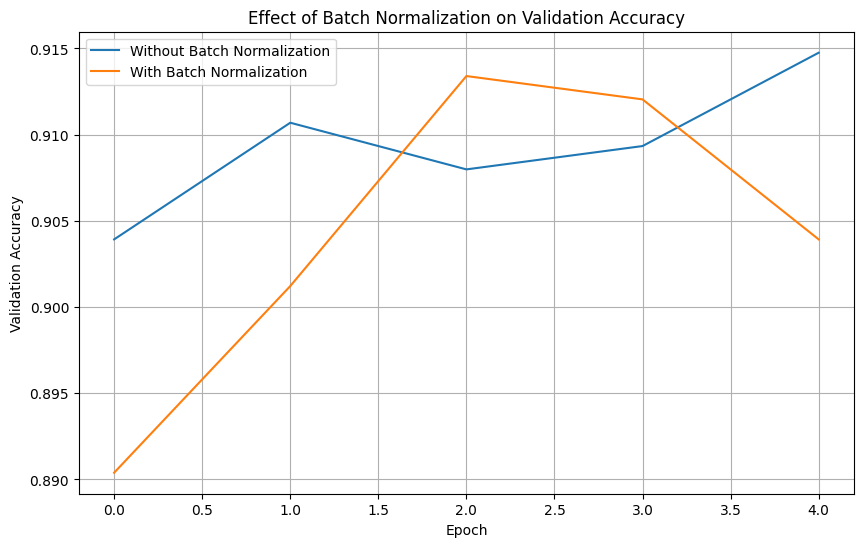

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_without_bn.history["val_accuracy"],
    label="Without Batch Normalization"
)

plt.plot(
    history_with_bn.history["val_accuracy"],
    label="With Batch Normalization"
)

plt.title("Effect of Batch Normalization on Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print(
    "Without BN:",
    history_without_bn.history["val_accuracy"][-1]
)

print(
    "With BN:",
    history_with_bn.history["val_accuracy"][-1]
)

Without BN: 0.9147496819496155
With BN: 0.9039242267608643


In [ ]:
optimizers = {
    "SGD": tf.keras.optimizers.SGD(learning_rate=0.001),

    "Momentum": tf.keras.optimizers.SGD(
        learning_rate=0.001,
        momentum=0.9
    ),

    "RMSProp": tf.keras.optimizers.RMSprop(
        learning_rate=0.001
    ),

    "Adam": tf.keras.optimizers.Adam(
        learning_rate=0.001
    )
}

In [ ]:
def create_optimizer_model():

    base_model = tf.keras.applications.MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    base_model.trainable = False

    model = tf.keras.Sequential([
        base_model,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(
            37,
            activation="softmax"
        )
    ])

    return model

In [ ]:
import time
optimizer_histories = {}
optimizer_results = {}

EPOCHS = 5

for name, optimizer in optimizers.items():

    print(f"\nTraining with {name}...")

    model_opt = create_optimizer_model()

    model_opt.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start_time = time.time()

    history = model_opt.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )

    training_time = time.time() - start_time

    optimizer_histories[name] = history
    optimizer_results[name] = {
        "training_time": training_time,
        "final_loss": history.history["loss"][-1],
        "best_val_accuracy": max(history.history["val_accuracy"])
    }


Training with SGD...
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - accuracy: 0.0556 - loss: 3.6651 - val_accuracy: 0.1015 - val_loss: 3.3621
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 48ms/step - accuracy: 0.1871 - loss: 3.0971 - val_accuracy: 0.2476 - val_loss: 2.8671
Epoch 3/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 46ms/step - accuracy: 0.3681 - loss: 2.6438 - val_accuracy: 0.4614 - val_loss: 2.4528
Epoch 4/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 20s 40ms/step - accuracy: 0.5414 - loss: 2.2631 - val_accuracy: 0.5900 - val_loss: 2.1056
Epoch 5/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 48ms/step - accuracy: 0.6507 - loss: 1.9469 - val_accuracy: 0.6820 - val_loss: 1.8206

Training with Momentum...
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - accuracy: 0.5321 - loss: 2.1300 - val_accuracy: 0.8241 - val_loss: 1.0204
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 47ms/step - accuracy: 0.8594 - loss: 0.7632 - val_accuracy: 0.8714 - val_loss: 0.5988
Epoch 3/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 43m

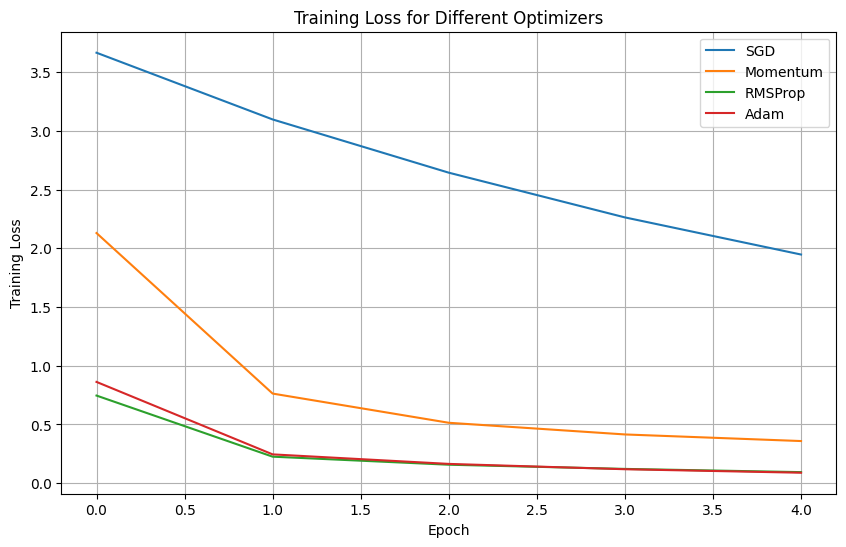

In [ ]:
plt.figure(figsize=(10, 6))

for name, history in optimizer_histories.items():
    plt.plot(
        history.history["loss"],
        label=name
    )

plt.title("Training Loss for Different Optimizers")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.legend()
plt.grid(True)
plt.show()

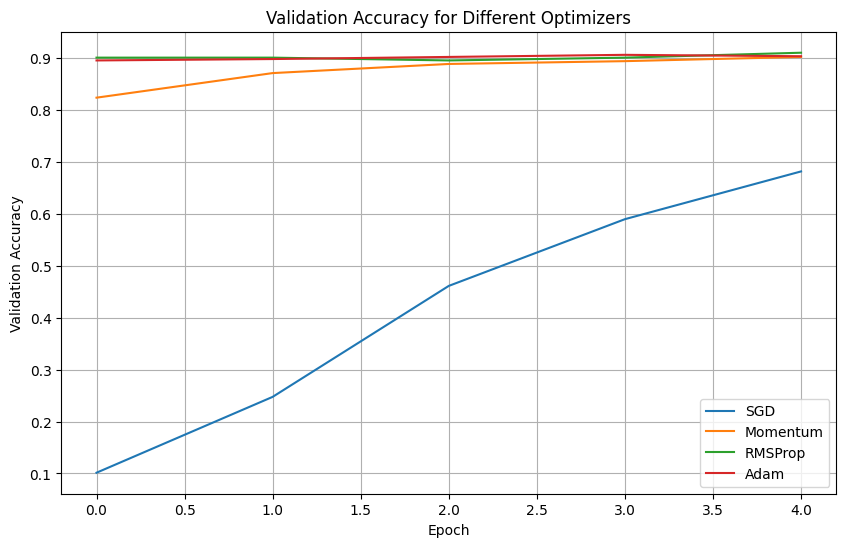

In [ ]:
plt.figure(figsize=(10, 6))

for name, history in optimizer_histories.items():
    plt.plot(
        history.history["val_accuracy"],
        label=name
    )

plt.title("Validation Accuracy for Different Optimizers")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
for name, history in optimizer_histories.items():

    best_epoch = (
        np.argmax(history.history["val_accuracy"]) + 1
    )

    print(
        f"{name:10s} | "
        f"Final Loss: {history.history['loss'][-1]:.4f} | "
        f"Best Val Acc: {max(history.history['val_accuracy']):.4f} | "
        f"Best Epoch: {best_epoch} | "
        f"Time: {optimizer_results[name]['training_time']:.2f}s"
    )

SGD        | Final Loss: 1.9469 | Best Val Acc: 0.6820 | Best Epoch: 5 | Time: 128.04s
Momentum   | Final Loss: 0.3590 | Best Val Acc: 0.9026 | Best Epoch: 5 | Time: 126.19s
RMSProp    | Final Loss: 0.0945 | Best Val Acc: 0.9107 | Best Epoch: 5 | Time: 144.31s
Adam       | Final Loss: 0.0894 | Best Val Acc: 0.9066 | Best Epoch: 4 | Time: 151.35s


In [ ]:
def create_hyperparameter_model(dropout_rate=0.0):

    base_model = tf.keras.applications.MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    base_model.trainable = False

    model = tf.keras.Sequential([
        base_model,
        tf.keras.layers.GlobalAveragePooling2D(),
    ])

    if dropout_rate > 0:
        model.add(tf.keras.layers.Dropout(dropout_rate))

    model.add(
        tf.keras.layers.Dense(
            37,
            activation="softmax"
        )
    )

    return model

In [ ]:
def compile_and_train(
    learning_rate=0.001,
    dropout_rate=0.0,
    optimizer_name="Adam",
    batch_size=32,
    epochs=5
):

    model = create_hyperparameter_model(dropout_rate)

    if optimizer_name == "SGD":
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=learning_rate
        )
    else:
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Recreate datasets with the requested batch size
    train_data = (
        tf.data.Dataset.from_tensor_slices(
            (train_paths, train_labels)
        )
        .shuffle(len(train_paths))
        .map(
            load_and_preprocess,
            num_parallel_calls=tf.data.AUTOTUNE
        )
        .batch(batch_size)
        .prefetch(tf.data.AUTOTUNE)
    )

    val_data = (
        tf.data.Dataset.from_tensor_slices(
            (val_paths, val_labels)
        )
        .map(
            load_and_preprocess,
            num_parallel_calls=tf.data.AUTOTUNE
        )
        .batch(batch_size)
        .prefetch(tf.data.AUTOTUNE)
    )

    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=epochs,
        verbose=1
    )

    return model, history


Training with Learning Rate = 0.001
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 43s 112ms/step - accuracy: 0.7850 - loss: 0.8648 - val_accuracy: 0.8945 - val_loss: 0.3430
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 25s 60ms/step - accuracy: 0.9352 - loss: 0.2478 - val_accuracy: 0.9080 - val_loss: 0.2857
Epoch 3/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.9552 - loss: 0.1674 - val_accuracy: 0.8999 - val_loss: 0.2736
Epoch 4/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.9711 - loss: 0.1185 - val_accuracy: 0.9080 - val_loss: 0.2565
Epoch 5/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 24s 46ms/step - accuracy: 0.9817 - loss: 0.0901 - val_accuracy: 0.9039 - val_loss: 0.2582
Learning Rate = 0.001 | Best Validation Accuracy = 90.80%

Training with Learning Rate = 0.0001
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 48s 118ms/step - accuracy: 0.3236 - loss: 2.7730 - val_accuracy: 0.6360 - val_loss: 1.9041
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 23s 46ms/step - accuracy: 0.7458 - loss: 1.4176 - va

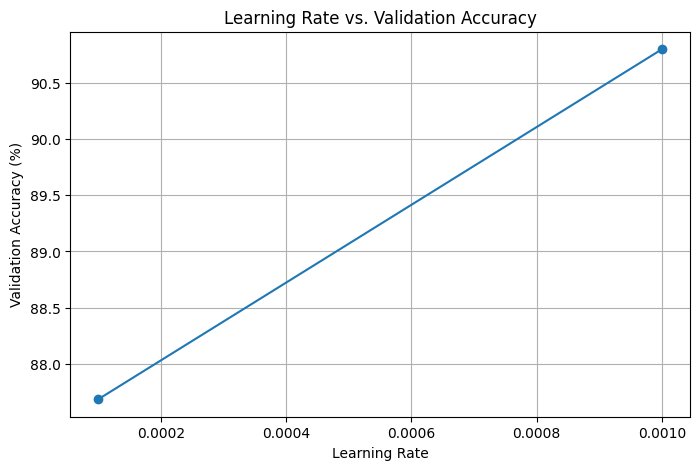

In [ ]:
# Hyperparameter Tuning — Learning Rate
# Compare 0.001 vs 0.0001
# All other settings kept fixed

learning_rates = [0.001, 0.0001]
lr_results = {}

for lr in learning_rates:

    print(f"\nTraining with Learning Rate = {lr}")

    model = create_hyperparameter_model(dropout_rate=0)

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=lr
    )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=5,
        verbose=1
    )

    lr_results[lr] = history

    print(
        f"Learning Rate = {lr} | "
        f"Best Validation Accuracy = "
        f"{max(history.history['val_accuracy']) * 100:.2f}%"
    )


# Plot 8 — Learning Rate vs Validation Accuracy

lr_values = list(lr_results.keys())

lr_accuracies = [
    max(history.history["val_accuracy"]) * 100
    for history in lr_results.values()
]

plt.figure(figsize=(8, 5))

plt.plot(
    lr_values,
    lr_accuracies,
    marker="o"
)

plt.title("Learning Rate vs. Validation Accuracy")
plt.xlabel("Learning Rate")
plt.ylabel("Validation Accuracy (%)")
plt.grid(True)

plt.show()


Training with Batch Size = 16
Epoch 1/5
370/370 ━━━━━━━━━━━━━━━━━━━━ 58s 106ms/step - accuracy: 0.8166 - loss: 0.6955 - val_accuracy: 0.8877 - val_loss: 0.3423
Epoch 2/5
370/370 ━━━━━━━━━━━━━━━━━━━━ 46s 48ms/step - accuracy: 0.9405 - loss: 0.2101 - val_accuracy: 0.8796 - val_loss: 0.3207
Epoch 3/5
370/370 ━━━━━━━━━━━━━━━━━━━━ 21s 48ms/step - accuracy: 0.9636 - loss: 0.1327 - val_accuracy: 0.8972 - val_loss: 0.2844
Epoch 4/5
370/370 ━━━━━━━━━━━━━━━━━━━━ 20s 47ms/step - accuracy: 0.9812 - loss: 0.0874 - val_accuracy: 0.8890 - val_loss: 0.2932
Epoch 5/5
370/370 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - accuracy: 0.9880 - loss: 0.0622 - val_accuracy: 0.8999 - val_loss: 0.2817
Batch Size = 16 | Best Validation Accuracy = 89.99%

Training with Batch Size = 32
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 37s 154ms/step - accuracy: 0.7838 - loss: 0.8750 - val_accuracy: 0.8999 - val_loss: 0.3471
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 16s 85ms/step - accuracy: 0.9327 - loss: 0.2458 - val_accuracy: 0.8999 

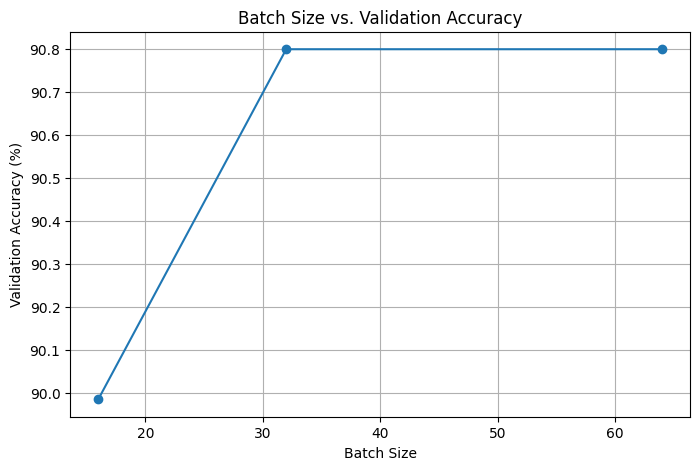

In [ ]:
# Hyperparameter Tuning — Batch Size
# Compare 16, 32 and 64

batch_sizes = [16, 32, 64]
batch_results = {}

for bs in batch_sizes:

    print(f"\nTraining with Batch Size = {bs}")

    model, history = compile_and_train(
        learning_rate=0.001,
        dropout_rate=0,
        optimizer_name="Adam",
        batch_size=bs,
        epochs=5
    )

    batch_results[bs] = history

    print(
        f"Batch Size = {bs} | "
        f"Best Validation Accuracy = "
        f"{max(history.history['val_accuracy']) * 100:.2f}%"
    )


# Plot 9 — Batch Size vs Validation Accuracy

batch_values = list(batch_results.keys())

batch_accuracies = [
    max(history.history["val_accuracy"]) * 100
    for history in batch_results.values()
]

plt.figure(figsize=(8, 5))

plt.plot(
    batch_values,
    batch_accuracies,
    marker="o"
)

plt.title("Batch Size vs. Validation Accuracy")
plt.xlabel("Batch Size")
plt.ylabel("Validation Accuracy (%)")
plt.grid(True)

plt.show()


Training with Dropout Rate = 0
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 36s 151ms/step - accuracy: 0.7886 - loss: 0.8624 - val_accuracy: 0.8796 - val_loss: 0.3636
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 17s 91ms/step - accuracy: 0.9325 - loss: 0.2472 - val_accuracy: 0.8877 - val_loss: 0.3069
Epoch 3/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 16s 85ms/step - accuracy: 0.9555 - loss: 0.1663 - val_accuracy: 0.8999 - val_loss: 0.2864
Epoch 4/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 20s 84ms/step - accuracy: 0.9718 - loss: 0.1186 - val_accuracy: 0.9053 - val_loss: 0.2714
Epoch 5/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 89ms/step - accuracy: 0.9787 - loss: 0.0913 - val_accuracy: 0.9093 - val_loss: 0.2551
Dropout Rate = 0 | Best Validation Accuracy = 90.93%

Training with Dropout Rate = 0.25
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 39s 154ms/step - accuracy: 0.7492 - loss: 0.9761 - val_accuracy: 0.9012 - val_loss: 0.3568
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 16s 84ms/step - accuracy: 0.9147 - loss: 0.2967 - val_accuracy: 0

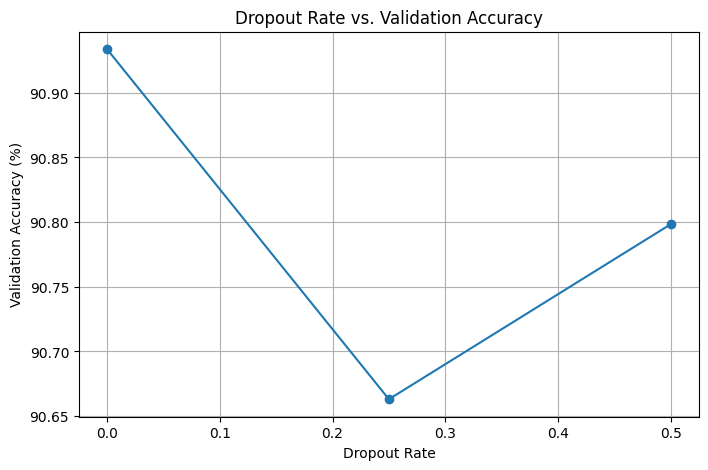

In [ ]:
# Hyperparameter Tuning — Dropout Rate
# Compare 0, 0.25 and 0.5

dropout_rates = [0, 0.25, 0.5]
dropout_results = {}

for dropout in dropout_rates:

    print(f"\nTraining with Dropout Rate = {dropout}")

    model, history = compile_and_train(
        learning_rate=0.001,
        dropout_rate=dropout,
        optimizer_name="Adam",
        batch_size=32,
        epochs=5
    )

    dropout_results[dropout] = history

    print(
        f"Dropout Rate = {dropout} | "
        f"Best Validation Accuracy = "
        f"{max(history.history['val_accuracy']) * 100:.2f}%"
    )


# Plot 10 — Dropout Rate vs Validation Accuracy

dropout_values = list(dropout_results.keys())

dropout_accuracies = [
    max(history.history["val_accuracy"]) * 100
    for history in dropout_results.values()
]

plt.figure(figsize=(8, 5))

plt.plot(
    dropout_values,
    dropout_accuracies,
    marker="o"
)

plt.title("Dropout Rate vs. Validation Accuracy")
plt.xlabel("Dropout Rate")
plt.ylabel("Validation Accuracy (%)")
plt.grid(True)

plt.show()

In [ ]:
# Fine-Tuning Learning Rate Experiment
# Frozen MobileNetV2 base
# Compare 1e-4 and 1e-5

fine_tune_lr = [1e-4, 1e-5]
fine_tune_lr_results = {}

for lr in fine_tune_lr:

    print(f"\nFine-Tuning Learning Rate = {lr}")

    base_model = tf.keras.applications.MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    base_model.trainable = False

    model = tf.keras.Sequential([
        base_model,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(37, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=lr
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=5,
        verbose=1
    )

    fine_tune_lr_results[lr] = history

    print(
        f"Learning Rate = {lr} | "
        f"Best Validation Accuracy = "
        f"{max(history.history['val_accuracy']) * 100:.2f}%"
    )


Fine-Tuning Learning Rate = 0.0001
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 72s 205ms/step - accuracy: 0.2985 - loss: 2.8433 - val_accuracy: 0.6319 - val_loss: 1.9398
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 39s 45ms/step - accuracy: 0.7370 - loss: 1.4581 - val_accuracy: 0.8173 - val_loss: 1.0974
Epoch 3/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 20s 40ms/step - accuracy: 0.8466 - loss: 0.8945 - val_accuracy: 0.8769 - val_loss: 0.7594
Epoch 4/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 27s 46ms/step - accuracy: 0.8848 - loss: 0.6480 - val_accuracy: 0.8809 - val_loss: 0.6008
Epoch 5/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 47ms/step - accuracy: 0.9031 - loss: 0.5163 - val_accuracy: 0.8877 - val_loss: 0.5091
Learning Rate = 0.0001 | Best Validation Accuracy = 88.77%

Fine-Tuning Learning Rate = 1e-05
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 47s 111ms/step - accuracy: 0.0489 - loss: 3.7694 - val_accuracy: 0.0514 - val_loss: 3.6094
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 28s 48ms/step - accuracy: 0.0773 - loss: 3.4996 - val_a

In [ ]:
# Frozen Layers Experiment
# Compare Frozen Base vs Partial Unfreezing

best_ft_lr = 1e-4

frozen_layer_results = {}

for strategy in ["Frozen Base", "Partial Unfreezing"]:

    print(f"\nStrategy: {strategy}")

    base_model = tf.keras.applications.MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    if strategy == "Frozen Base":
        base_model.trainable = False

    else:
        base_model.trainable = True

        # Freeze earlier layers
        for layer in base_model.layers[:-30]:
            layer.trainable = False

        # Keep Batch Normalization layers frozen
        for layer in base_model.layers:
            if isinstance(layer, tf.keras.layers.BatchNormalization):
                layer.trainable = False

    model = tf.keras.Sequential([
        base_model,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(37, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=best_ft_lr
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=5,
        verbose=1
    )

    frozen_layer_results[strategy] = history

    print(
        f"{strategy} | "
        f"Best Validation Accuracy = "
        f"{max(history.history['val_accuracy']) * 100:.2f}%"
    )


Strategy: Frozen Base
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 44s 116ms/step - accuracy: 0.2852 - loss: 2.8223 - val_accuracy: 0.6171 - val_loss: 1.8968
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 24s 47ms/step - accuracy: 0.7299 - loss: 1.4569 - val_accuracy: 0.7930 - val_loss: 1.0799
Epoch 3/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 42ms/step - accuracy: 0.8364 - loss: 0.9041 - val_accuracy: 0.8525 - val_loss: 0.7559
Epoch 4/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 45ms/step - accuracy: 0.8748 - loss: 0.6595 - val_accuracy: 0.8674 - val_loss: 0.6006
Epoch 5/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 46ms/step - accuracy: 0.8934 - loss: 0.5284 - val_accuracy: 0.8809 - val_loss: 0.5123
Frozen Base | Best Validation Accuracy = 88.09%

Strategy: Partial Unfreezing
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 48s 129ms/step - accuracy: 0.7730 - loss: 0.8013 - val_accuracy: 0.8836 - val_loss: 0.3573
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 23s 49ms/step - accuracy: 0.9295 - loss: 0.2227 - val_accuracy: 0.8958 - val_loss: 0

In [ ]:
# ============================================================
# 10. TRANSFER LEARNING AND FINE-TUNING
# ============================================================

# Use the best fine-tuning learning rate obtained earlier
best_ft_lr = 1e-4


# ============================================================
# CASE A — FEATURE EXTRACTION
# Pretrained MobileNetV2 → Freeze Base → New Classifier
# ============================================================

base_feature = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_feature.trainable = False

feature_model = tf.keras.Sequential([
    base_feature,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(37, activation="softmax")
])

feature_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_feature = feature_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    verbose=1
)


# ============================================================
# CASE B — FINE-TUNING
# Pretrained MobileNetV2 → Unfreeze Selected Layers
# ============================================================

base_finetune = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_finetune.trainable = True

# Freeze earlier layers
for layer in base_finetune.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_finetune.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

fine_tune_model = tf.keras.Sequential([
    base_finetune,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(37, activation="softmax")
])

fine_tune_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=best_ft_lr
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_finetune = fine_tune_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    verbose=1
)


# ============================================================
# RESULTS
# ============================================================

print("\n===== RESULTS =====")

print(
    "Feature Extraction Best Validation Accuracy:",
    max(history_feature.history["val_accuracy"]) * 100
)

print(
    "Fine-Tuning Best Validation Accuracy:",
    max(history_finetune.history["val_accuracy"]) * 100
)

Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 44s 111ms/step - accuracy: 0.7884 - loss: 0.8518 - val_accuracy: 0.9093 - val_loss: 0.3520
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 46ms/step - accuracy: 0.9337 - loss: 0.2467 - val_accuracy: 0.9039 - val_loss: 0.2965
Epoch 3/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 47ms/step - accuracy: 0.9567 - loss: 0.1653 - val_accuracy: 0.8999 - val_loss: 0.2649
Epoch 4/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 48ms/step - accuracy: 0.9692 - loss: 0.1201 - val_accuracy: 0.9053 - val_loss: 0.2628
Epoch 5/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 0.9807 - loss: 0.0912 - val_accuracy: 0.9039 - val_loss: 0.2681
Epoch 1/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 45s 121ms/step - accuracy: 0.7686 - loss: 0.8191 - val_accuracy: 0.8674 - val_loss: 0.3803
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 48ms/step - accuracy: 0.9274 - loss: 0.2287 - val_accuracy: 0.8809 - val_loss: 0.3496
Epoch 3/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 53ms/step - accuracy: 0.9662 - loss: 0.1129 - val_ac

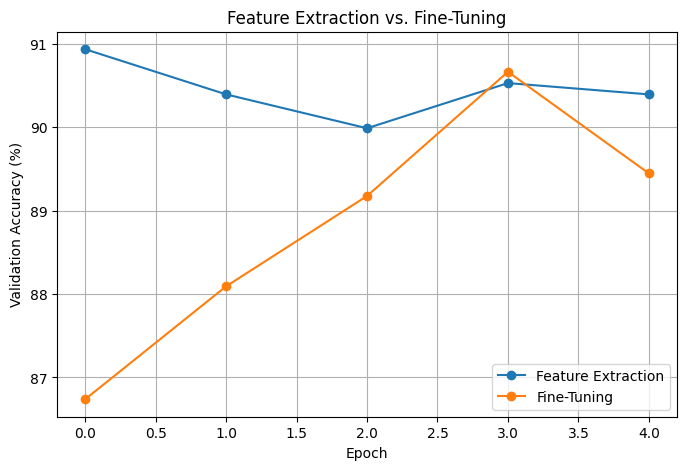

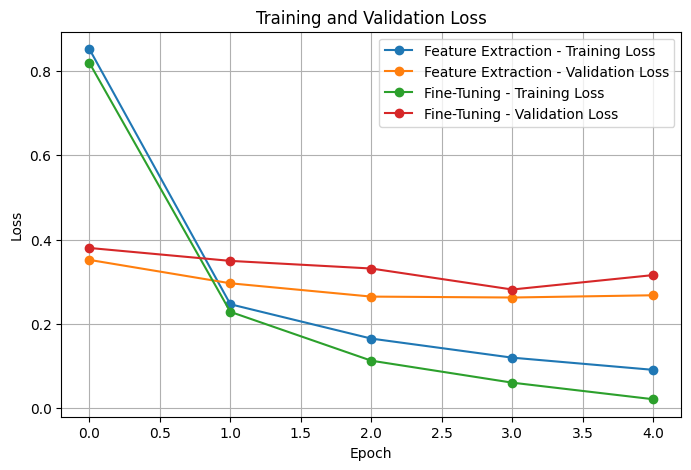

In [ ]:
import matplotlib.pyplot as plt


# ============================================================
# PLOT 11 — FEATURE EXTRACTION VS FINE-TUNING
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    np.array(history_feature.history["val_accuracy"]) * 100,
    marker="o",
    label="Feature Extraction"
)

plt.plot(
    np.array(history_finetune.history["val_accuracy"]) * 100,
    marker="o",
    label="Fine-Tuning"
)

plt.title("Feature Extraction vs. Fine-Tuning")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# PLOT 12 — TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_feature.history["loss"],
    marker="o",
    label="Feature Extraction - Training Loss"
)

plt.plot(
    history_feature.history["val_loss"],
    marker="o",
    label="Feature Extraction - Validation Loss"
)

plt.plot(
    history_finetune.history["loss"],
    marker="o",
    label="Fine-Tuning - Training Loss"
)

plt.plot(
    history_finetune.history["val_loss"],
    marker="o",
    label="Fine-Tuning - Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
configs = {

    "C1": {
        "learning_rate": 0.001,
        "batch_size": 32,
        "dropout": 0.0
    },

    "C2": {
        "learning_rate": 0.001,
        "batch_size": 32,
        "dropout": 0.25
    },

    "C3": {
        "learning_rate": 0.001,
        "batch_size": 32,
        "dropout": 0.5
    }

}

print("Configurations:")
for name, config in configs.items():
    print(name, config)

Configurations:
C1 {'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.0}
C2 {'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.25}
C3 {'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.5}


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold

print("TensorFlow version:", tf.__version__)
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = {}

for name, config in configs.items():

    print("\n" + "=" * 50)
    print("Configuration:", name)
    print(config)
    print("=" * 50)

    fold_scores = []

    for fold, (train_idx, val_idx) in enumerate(
        kf.split(X),
        start=1
    ):

        print(f"\nFold {fold}/5")

        X_train = X[train_idx]
        y_train = y[train_idx]

        X_val = X[val_idx]
        y_val = y[val_idx]

        # Small classifier only
        model = tf.keras.Sequential([

            tf.keras.layers.Input(
                shape=(1280,)
            ),

            tf.keras.layers.Dropout(
                config["dropout"]
            ),

            tf.keras.layers.Dense(
                NUM_CLASSES,
                activation="softmax"
            )
        ])

        model.compile(

            optimizer=tf.keras.optimizers.Adam(
                learning_rate=config["learning_rate"]
            ),

            loss="sparse_categorical_crossentropy",

            metrics=["accuracy"]
        )

        model.fit(

            X_train,
            y_train,

            epochs=2,

            batch_size=config["batch_size"],

            verbose=0
        )

        _, accuracy = model.evaluate(
            X_val,
            y_val,
            verbose=0
        )

        accuracy_percent = accuracy * 100

        fold_scores.append(
            accuracy_percent
        )

        print(
            f"Fold {fold} Accuracy: "
            f"{accuracy_percent:.2f}%"
        )

        del model
        tf.keras.backend.clear_session()

    mean_accuracy = np.mean(
        fold_scores
    )

    std_accuracy = np.std(
        fold_scores
    )

    cv_results[name] = {

        "folds": fold_scores,

        "mean": mean_accuracy,

        "std": std_accuracy
    }

    print(
        f"\n{name} Mean ± SD: "
        f"{mean_accuracy:.2f} ± "
        f"{std_accuracy:.2f}%"
    )

TensorFlow version: 2.20.0

Configuration: C1
{'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.0}


NameError: name 'X' is not defined